# EfficientNet-V2-S Test Results

This notebook reads `outputs/test_evaluation/efficientnet_v2_s_test_results.json` and visualizes the held-out test evaluation.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)


def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "outputs").exists():
            return candidate
    fallback = Path("/Users/jaumemalenacortes/Desktop/AABI/AAIB")
    return fallback if fallback.exists() else start

PROJECT_ROOT = find_project_root()
TEST_RESULTS_PATH = PROJECT_ROOT / "outputs" / "test_evaluation" / "efficientnet_v2_s_test_results.json"
DISPLAY_NAME = "EfficientNet-V2-S"

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"TEST_RESULTS_PATH: {TEST_RESULTS_PATH}")
print(f"Exists: {TEST_RESULTS_PATH.exists()}")


PROJECT_ROOT: /Users/jaumemalenacortes/Desktop/AABI/AAIB
TEST_RESULTS_PATH: /Users/jaumemalenacortes/Desktop/AABI/AAIB/outputs/test_evaluation/efficientnet_v2_s_test_results.json
Exists: True


In [2]:
if not TEST_RESULTS_PATH.exists():
    raise FileNotFoundError(f"Missing test results JSON: {TEST_RESULTS_PATH}")

with open(TEST_RESULTS_PATH) as f:
    test_res = json.load(f)

print(f"Loaded: {TEST_RESULTS_PATH.name}")
print(f"Test images: {test_res['n_images']}")
print(f"Models ensembled: {test_res['n_models_ensembled']}")
print("Run dirs:")
for run_dir in test_res.get("run_dirs", []):
    print(f"  - {run_dir}")


Loaded: efficientnet_v2_s_test_results.json
Test images: 6284
Models ensembled: 1
Run dirs:
  - /home/u231612/outputs/runs/efficientnet_v2_s_fold0_20260529_154504


In [3]:
m05 = test_res.get("metrics_at_0.5", {})
mcal = test_res.get("metrics_at_calibrated_threshold") or {}

def safe_div(num, den):
    return num / den if den else np.nan

rows = [{
    "Threshold": "0.5",
    "PR-AUC": round(float(m05.get("pr_auc", np.nan)), 4),
    "MCC": round(float(m05.get("mcc", np.nan)), 4),
    "NPV": round(float(m05.get("npv", np.nan)), 4),
    "Precision": round(safe_div(m05.get("tp", 0), m05.get("tp", 0) + m05.get("fp", 0)), 4),
    "Recall": round(safe_div(m05.get("tp", 0), m05.get("tp", 0) + m05.get("fn", 0)), 4),
    "TP": m05.get("tp"),
    "TN": m05.get("tn"),
    "FP": m05.get("fp"),
    "FN": m05.get("fn"),
}]

if mcal:
    rows.append({
        "Threshold": f"t_safe ({float(mcal['threshold']):.3f})",
        "PR-AUC": np.nan,
        "MCC": np.nan,
        "NPV": round(float(mcal.get("npv", np.nan)), 4),
        "Precision": round(float(mcal.get("precision", np.nan)), 4),
        "Recall": round(float(mcal.get("recall", np.nan)), 4),
        "TP": mcal.get("tp"),
        "TN": mcal.get("tn"),
        "FP": mcal.get("fp"),
        "FN": mcal.get("fn"),
    })

metrics_df = pd.DataFrame(rows).set_index("Threshold")
display(metrics_df)

speed = test_res.get("speed", {})
if speed:
    display(pd.DataFrame([speed]).rename(index={0: "Speed"}))


,PR-AUC,MCC,NPV,Precision,Recall,TP,TN,FP,FN
Threshold,,,,,,,,,
0.5,0.1585,0.2968,0.9815,0.1797,0.7655,284,4617,1296,87
t_safe (0.642),NaN,NaN,0.9756,0.2069,0.6658,247,4966,947,124


,images,total_seconds,images_per_sec
Speed,6284,8.94,702.9


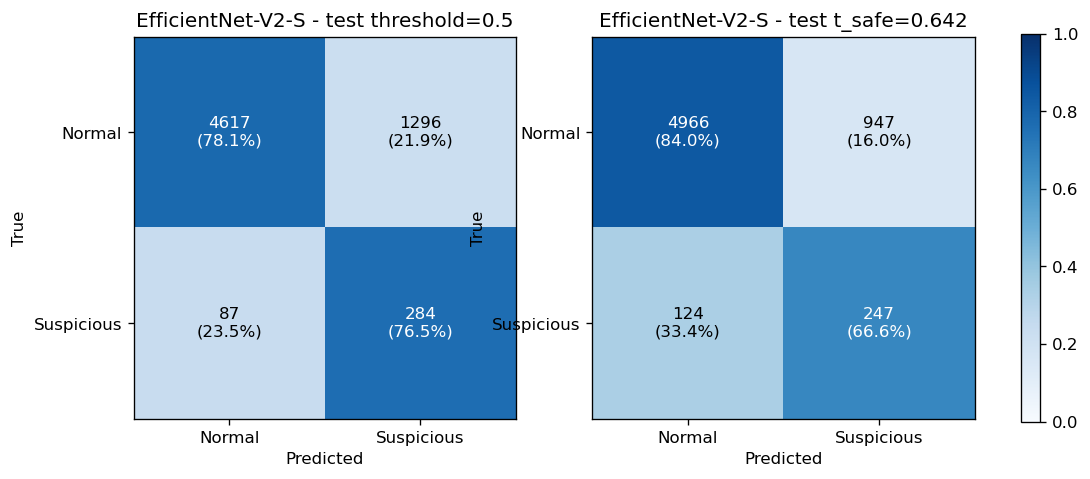

In [4]:
def plot_cm_from_counts(metrics: dict, title: str, ax):
    cm = np.array([
        [metrics.get("tn", 0), metrics.get("fp", 0)],
        [metrics.get("fn", 0), metrics.get("tp", 0)],
    ], dtype=int)
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_pct = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
    im = ax.imshow(cm_pct, vmin=0, vmax=1, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Normal", "Suspicious"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Normal", "Suspicious"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{cm[i, j]}\n({cm_pct[i, j]:.1%})",
                ha="center", va="center",
                color="white" if cm_pct[i, j] > 0.5 else "black",
            )
    return im

ncols = 2 if mcal else 1
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 4.2))
axes = np.atleast_1d(axes)
im = plot_cm_from_counts(m05, f"{DISPLAY_NAME} - test threshold=0.5", axes[0])
if mcal:
    plot_cm_from_counts(mcal, f"{DISPLAY_NAME} - test t_safe={mcal['threshold']:.3f}", axes[1])
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.046)
plt.show()


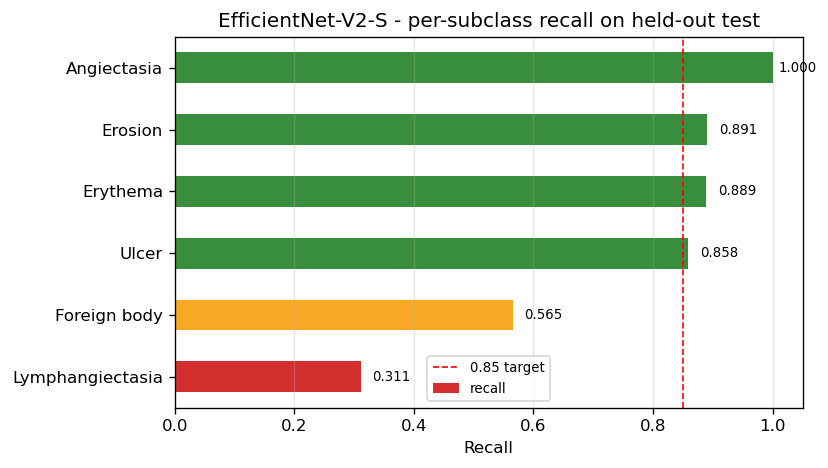

In [5]:
sub = pd.Series(test_res.get("subclass_recall", {}), name="recall").sort_values()
if sub.empty:
    print("No subclass recall found in test results.")
else:
    colors = ["#d32f2f" if v < 0.5 else "#f9a825" if v < 0.85 else "#388e3c" for v in sub]
    fig, ax = plt.subplots(figsize=(max(7, len(sub) * 0.8), 4))
    sub.plot(kind="barh", ax=ax, color=colors)
    ax.axvline(0.85, color="red", linestyle="--", linewidth=1, label="0.85 target")
    ax.set_xlim(0, 1.05)
    ax.set_xlabel("Recall")
    ax.set_title(f"{DISPLAY_NAME} - per-subclass recall on held-out test")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis="x")
    for y, value in enumerate(sub):
        ax.text(min(value + 0.02, 1.01), y, f"{value:.3f}", va="center", fontsize=8)
    fig.tight_layout()
    plt.show()
